# Evaluating your clustering

Clustering is usually an exploratory technique, and it's not uncommon to use it against multiple dimensions with many runs.  Although there is no "objective" way to determine if a clustering result is _good_, there are a few common scores we can calculate to at least be able to detect what clustering results are best in our specific situation.

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

penguins_df = sns.load_dataset('penguins')

penguins_df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


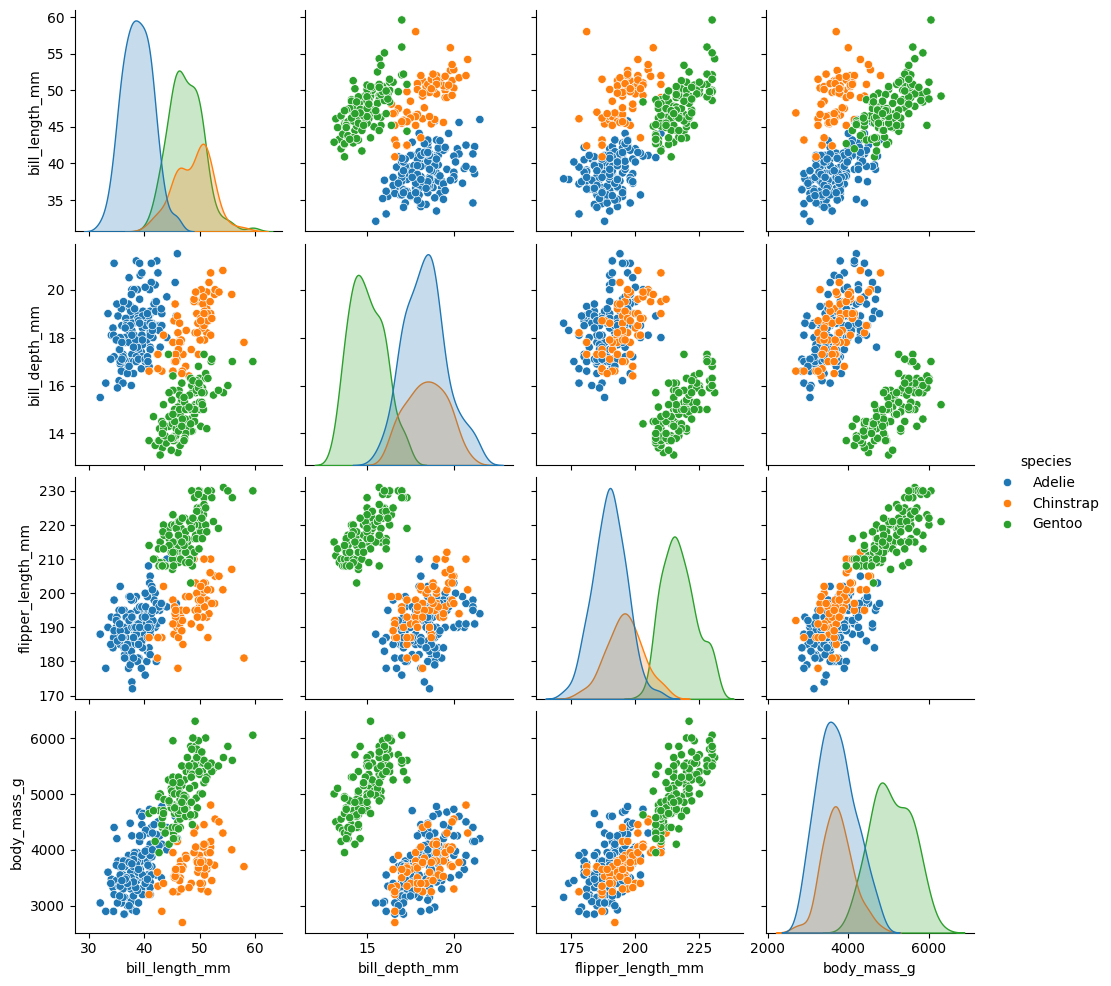

In [3]:
sns.pairplot(penguins_df, hue='species')
plt.show()

In [4]:
# normalize data
scale_norm = MinMaxScaler()
numeric_cols = penguins_df.select_dtypes(include='number').columns
penguins_scaled = pd.DataFrame(
    scale_norm.fit_transform(penguins_df[numeric_cols].dropna()),
    columns=numeric_cols
)
penguins_scaled.dropna(inplace=True)


In [5]:
penguins_df[numeric_cols] = penguins_scaled
penguins_df.dropna(inplace=True)

In [6]:
from sklearn.cluster import KMeans

# Cluster 1: bill_length_mm, bill_depth_mm, k=3
kmeans1 = KMeans(n_clusters=3, random_state=42)
kmeans1_result = kmeans1.fit_predict(penguins_df[["bill_length_mm", "bill_depth_mm"]].dropna())
penguins_df["cluster_1"] = kmeans1_result

# Cluster 2: body_mass_g, bill_depth_mm, k=2
kmeans2 = KMeans(n_clusters=2, random_state=42)
kmeans2_result = kmeans2.fit_predict(penguins_df[["body_mass_g", "bill_depth_mm"]].dropna())
penguins_df["cluster_2"] = kmeans2_result

# Cluster 3: flipper_length_mm, bill_length_mm, k=3
kmeans3 = KMeans(n_clusters=3, random_state=42)
kmeans3_result = kmeans3.fit_predict(penguins_df[["flipper_length_mm", "bill_length_mm"]].dropna())
penguins_df["cluster_3"] = kmeans3_result

# Cluster 4: body_mass_g, flipper_length_mm, k=3
kmeans4 = KMeans(n_clusters=3, random_state=42)
kmeans4_result = kmeans4.fit_predict(penguins_df[["body_mass_g", "flipper_length_mm"]].dropna())
penguins_df["cluster_4"] = kmeans4_result

penguins_df


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,cluster_1,cluster_2,cluster_3,cluster_4
0,Adelie,Torgersen,0.254545,0.666667,0.152542,0.291667,Male,0,0,0,0
1,Adelie,Torgersen,0.269091,0.511905,0.237288,0.305556,Female,0,0,0,0
2,Adelie,Torgersen,0.298182,0.583333,0.389831,0.152778,Female,0,0,0,0
4,Adelie,Torgersen,0.261818,0.892857,0.305085,0.263889,Female,0,0,0,0
5,Adelie,Torgersen,0.247273,0.559524,0.152542,0.256944,Male,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
335,Gentoo,Biscoe,0.450909,0.309524,0.762712,0.604167,Male,1,1,1,1
337,Gentoo,Biscoe,0.549091,0.071429,0.711864,0.618056,Male,1,1,1,1
338,Gentoo,Biscoe,0.534545,0.142857,0.728814,0.597222,Female,1,1,1,1
340,Gentoo,Biscoe,0.476364,0.202381,0.677966,0.694444,Female,1,1,1,1


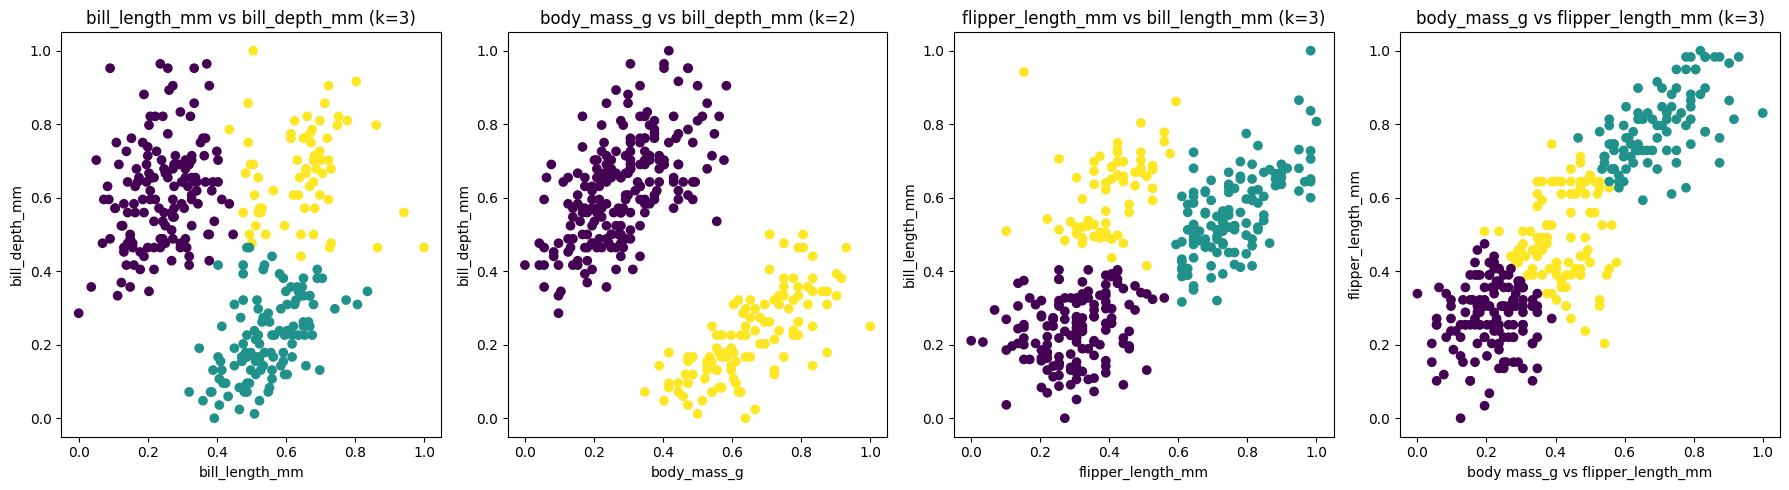

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].scatter(penguins_df["bill_length_mm"], penguins_df["bill_depth_mm"], c=penguins_df["cluster_1"], cmap="viridis", marker="o")
axes[0].set_title("bill_length_mm vs bill_depth_mm (k=3)")
axes[0].set_xlabel("bill_length_mm")
axes[0].set_ylabel("bill_depth_mm")

axes[1].scatter(penguins_df["body_mass_g"], penguins_df["bill_depth_mm"], c=penguins_df["cluster_2"], cmap="viridis", marker="o")
axes[1].set_title("body_mass_g vs bill_depth_mm (k=2)")
axes[1].set_xlabel("body_mass_g")
axes[1].set_ylabel("bill_depth_mm")

axes[2].scatter(penguins_df["flipper_length_mm"], penguins_df["bill_length_mm"], c=penguins_df["cluster_3"], cmap="viridis", marker="o")
axes[2].set_title("flipper_length_mm vs bill_length_mm (k=3)")
axes[2].set_xlabel("flipper_length_mm")
axes[2].set_ylabel("bill_length_mm")

axes[3].scatter(penguins_df["body_mass_g"], penguins_df["flipper_length_mm"], c=penguins_df["cluster_4"], cmap="viridis", marker="o")
axes[3].set_title("body_mass_g vs flipper_length_mm (k=3)")
axes[3].set_xlabel("body mass_g vs flipper_length_mm")
axes[3].set_ylabel("flipper_length_mm")

plt.tight_layout()
plt.show()


## Evaluation

Let's evaluate the results of the four clustering we have done, using the [Silhouette Score](https://en.wikipedia.org/wiki/Silhouette_(clustering)) and the [Calinski–Harabasz index](https://en.wikipedia.org/wiki/Calinski%E2%80%93Harabasz_index)

In [8]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score

# Silhouette
print("Silhouette score for clustering 1", silhouette_score(penguins_df[numeric_cols], kmeans1_result))
print("Silhouette score for clustering 2", silhouette_score(penguins_df[numeric_cols], kmeans2_result))
print("Silhouette score for clustering 3", silhouette_score(penguins_df[numeric_cols], kmeans3_result))
print("Silhouette score for clustering 4", silhouette_score(penguins_df[numeric_cols], kmeans4_result))

# Calinski-Harabasz
print("Calinski-harabasz index for clustering 1", calinski_harabasz_score(penguins_df[numeric_cols], kmeans1_result))
print("Calinski-harabasz index for clustering 2", calinski_harabasz_score(penguins_df[numeric_cols], kmeans2_result))
print("Calinski-harabasz index for clustering 3", calinski_harabasz_score(penguins_df[numeric_cols], kmeans3_result))
print("Calinski-harabasz index for clustering 4", calinski_harabasz_score(penguins_df[numeric_cols], kmeans4_result))

Silhouette score for clustering 1 0.4127382966396845
Silhouette score for clustering 2 0.5467144071139366
Silhouette score for clustering 3 0.41746182363584144
Silhouette score for clustering 4 0.2969435957741723
Calinski-harabasz index for clustering 1 291.72858159859425
Calinski-harabasz index for clustering 2 506.62181273114606
Calinski-harabasz index for clustering 3 370.09734603291037
Calinski-harabasz index for clustering 4 248.76679889382993


Clearly, some combinations of columns produced better scores, can you spot the best and the worst?

Note: these scores can and should be used also while determing the optimal K!

## Conclusions

Now that you have performed a good clustering, it's time to bring value to its result by properly creating tags.

Each record should now have a cluster tag (e.g.: a number from 1 to K); determine what are the common features for each cluster's records -> these should not be among the columns you have used to perform the clustering!

Now change every tag with an appropriate name. For example, all penguins belonging to a specific cluster might be Gentoo Males; you would then rename that cluster tag with "Gentoo Males".

If you can do this, perfect! We had a successful clustering!

If not, it's ok, it's perfectly fine to accept a failed attempt!